## Берем датасет Reuters-21578 и достаем из него заголовки                                   

In [13]:
%pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [14]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [15]:
import numpy as np
import pandas as pd

In [16]:
import html
import nltk
from nltk.corpus import reuters

nltk.download('reuters')

def load_reuters(split):
    ids = [f for f in reuters.fileids() if f.startswith(split + '/')]
    # ids = ['earn', 'acq', 'crude', 'trade', 'money-fx', 'interest', 'ship']
    texts = [html.unescape(reuters.raw(f)) for f in ids]
    labels = [reuters.categories(f) for f in ids]
    return texts, labels

def clean_text(text):
    text = html.unescape(text)
    title, _, body = text.partition('\n')
    text = f'{title.strip()}. {body}'
    text = TICKER.sub(' ', text)
    text = re.sub(r'[<>]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip().lower()

[nltk_data] Downloading package reuters to
[nltk_data]     C:\Users\382he\AppData\Roaming\nltk_data...
[nltk_data]   Package reuters is already up-to-date!


In [17]:
raw_train_texts, raw_train_labels = load_reuters('training')
raw_test_texts, raw_test_labels = load_reuters('test')

In [18]:
import re
TICKER = re.compile(r'<[A-Z]{1,5}(?:\.[A-Z]{1,3})*>')

text_train = [clean_text(t) for t in raw_train_texts]
text_test  = [clean_text(t) for t in raw_test_texts]

def single_label(texts, labels):
    pairs = [(t, l[0]) for t, l in zip(texts, labels) if len(l) == 1]
    return [t for t, _ in pairs], [l for _, l in pairs]

text_train1, tags_train1 = single_label(text_train, raw_train_labels)
text_test1,  tags_test1  = single_label(text_test, raw_test_labels)

In [19]:
print(len(text_train), len(text_test))

7769 3019


In [20]:
from collections import Counter

counts = Counter(tags_train1)
filtered_text_train1 = [val1 for val1, val2 in zip(text_train1, tags_train1) if counts[val2] >= 5]
filtered_tags_train1 = [val2 for val1, val2 in zip(text_train1, tags_train1) if counts[val2] >= 5] # фильтр чтобы sklearn не ругался на маленькое количество примеров в классах

text_train1, tags_train1 = filtered_text_train1, filtered_tags_train1
print(len(text_train1), len(text_test1))

6545 2583


## Получение эмбеддингов (Bag Of Words)

In [21]:
from sklearn.feature_extraction.text import CountVectorizer

# Полный BoW без фильтрации словаря. Матрица хранится в разреженном формате CSR:
# в памяти лежат только ненулевые счётчики (~0.3% ячеек), поэтому весь корпус занимает единицы МБ.
# Все модели sklearn (TruncatedSVD, LogisticRegression, KNN, KMeans...) принимают такую матрицу напрямую.
vectorizer = CountVectorizer()
X_train_bow = vectorizer.fit_transform(text_train1)   # fit только на train
X_test_bow  = vectorizer.transform(text_test1)        # слова, которых нет в словаре train, отбрасываются
vocab = vectorizer.get_feature_names_out()

In [22]:
# Табличный вид BoW: разреженный DataFrame, колонки — слова, строки — документы.
# Обычный pd.DataFrame(X.toarray()) развернул бы все нули и занял ~1.2 ГБ.
bow_df = pd.DataFrame.sparse.from_spmatrix(
    X_train_bow,
    columns=vocab,
    index=[f'{i+1}' for i in range(X_train_bow.shape[0])],
)
print(bow_df.shape, f'{bow_df.memory_usage().sum() / 2**20:.1f} МБ')

# слова первого документа по убыванию частоты
doc = bow_df.iloc[0]
doc[doc > 0].sort_values(ascending=False).head(16)

(6545, 21481) 5.1 МБ


and      23
at       20
the      18
to       14
dlrs     14
for      10
new       9
were      9
york      8
of        8
sales     7
cocoa     7
times     7
in        6
dec       6
are       5
Name: 1, dtype: Sparse[int64, 0]

In [23]:
# Если всё же нужна плотная матрица (numpy-операции, методы без поддержки sparse):
# счётчики маленькие, поэтому хватает uint8 — 1 байт на ячейку вместо 8 (~150 МБ вместо ~1.2 ГБ).
assert X_train_bow.max() <= np.iinfo(np.uint8).max
X_train_dense = X_train_bow.astype(np.uint8).toarray()
print(X_train_dense.shape, f'{X_train_dense.nbytes / 2**20:.0f} МБ')

(6545, 21481) 134 МБ


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import Normalizer
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsOneClassifier
from sklearn.model_selection import cross_validate

models = {
    "OvR": LinearSVC(C=1),
    "OvO": OneVsOneClassifier(LinearSVC(C=1)),
    "Crammer-Singer": LinearSVC(C=1, multi_class="crammer_singer"),
}

fitted = {}

for name, clf in models.items():
    pipe = make_pipeline(CountVectorizer(min_df=2, stop_words="english"),
                         Normalizer(), clf)
    r = cross_validate(pipe, text_train1, tags_train1, cv=5, scoring="f1_macro")
    fitted[name] = pipe.fit(text_train1, tags_train1)
    print('f1 score:', name, r["test_score"].mean().round(3), 'время обучения:', r["fit_time"].mean().round(2), 'сек.')

f1 score: OvR 0.8 время обучения: 2.02  сек
f1 score: OvO 0.8 время обучения: 2.02  сек
f1 score: Crammer-Singer 0.8 время обучения: 2.02  сек


## SVM на BoW
### Берем самые популярные темы

In [25]:
most_common_themes = Counter(tags_train1).most_common(20)
tags, counters = [], []
for theme in most_common_themes:
    tags.append(theme[0])
    counters.append(theme[1])

print([(tag, count) for tag, count in zip(tags,counters)])

[('earn', 2840), ('acq', 1596), ('crude', 253), ('trade', 250), ('money-fx', 222), ('interest', 191), ('money-supply', 123), ('ship', 108), ('sugar', 97), ('coffee', 90), ('gold', 70), ('gnp', 59), ('cpi', 54), ('cocoa', 46), ('grain', 41), ('reserves', 37), ('jobs', 37), ('ipi', 34), ('alum', 31), ('rubber', 31)]


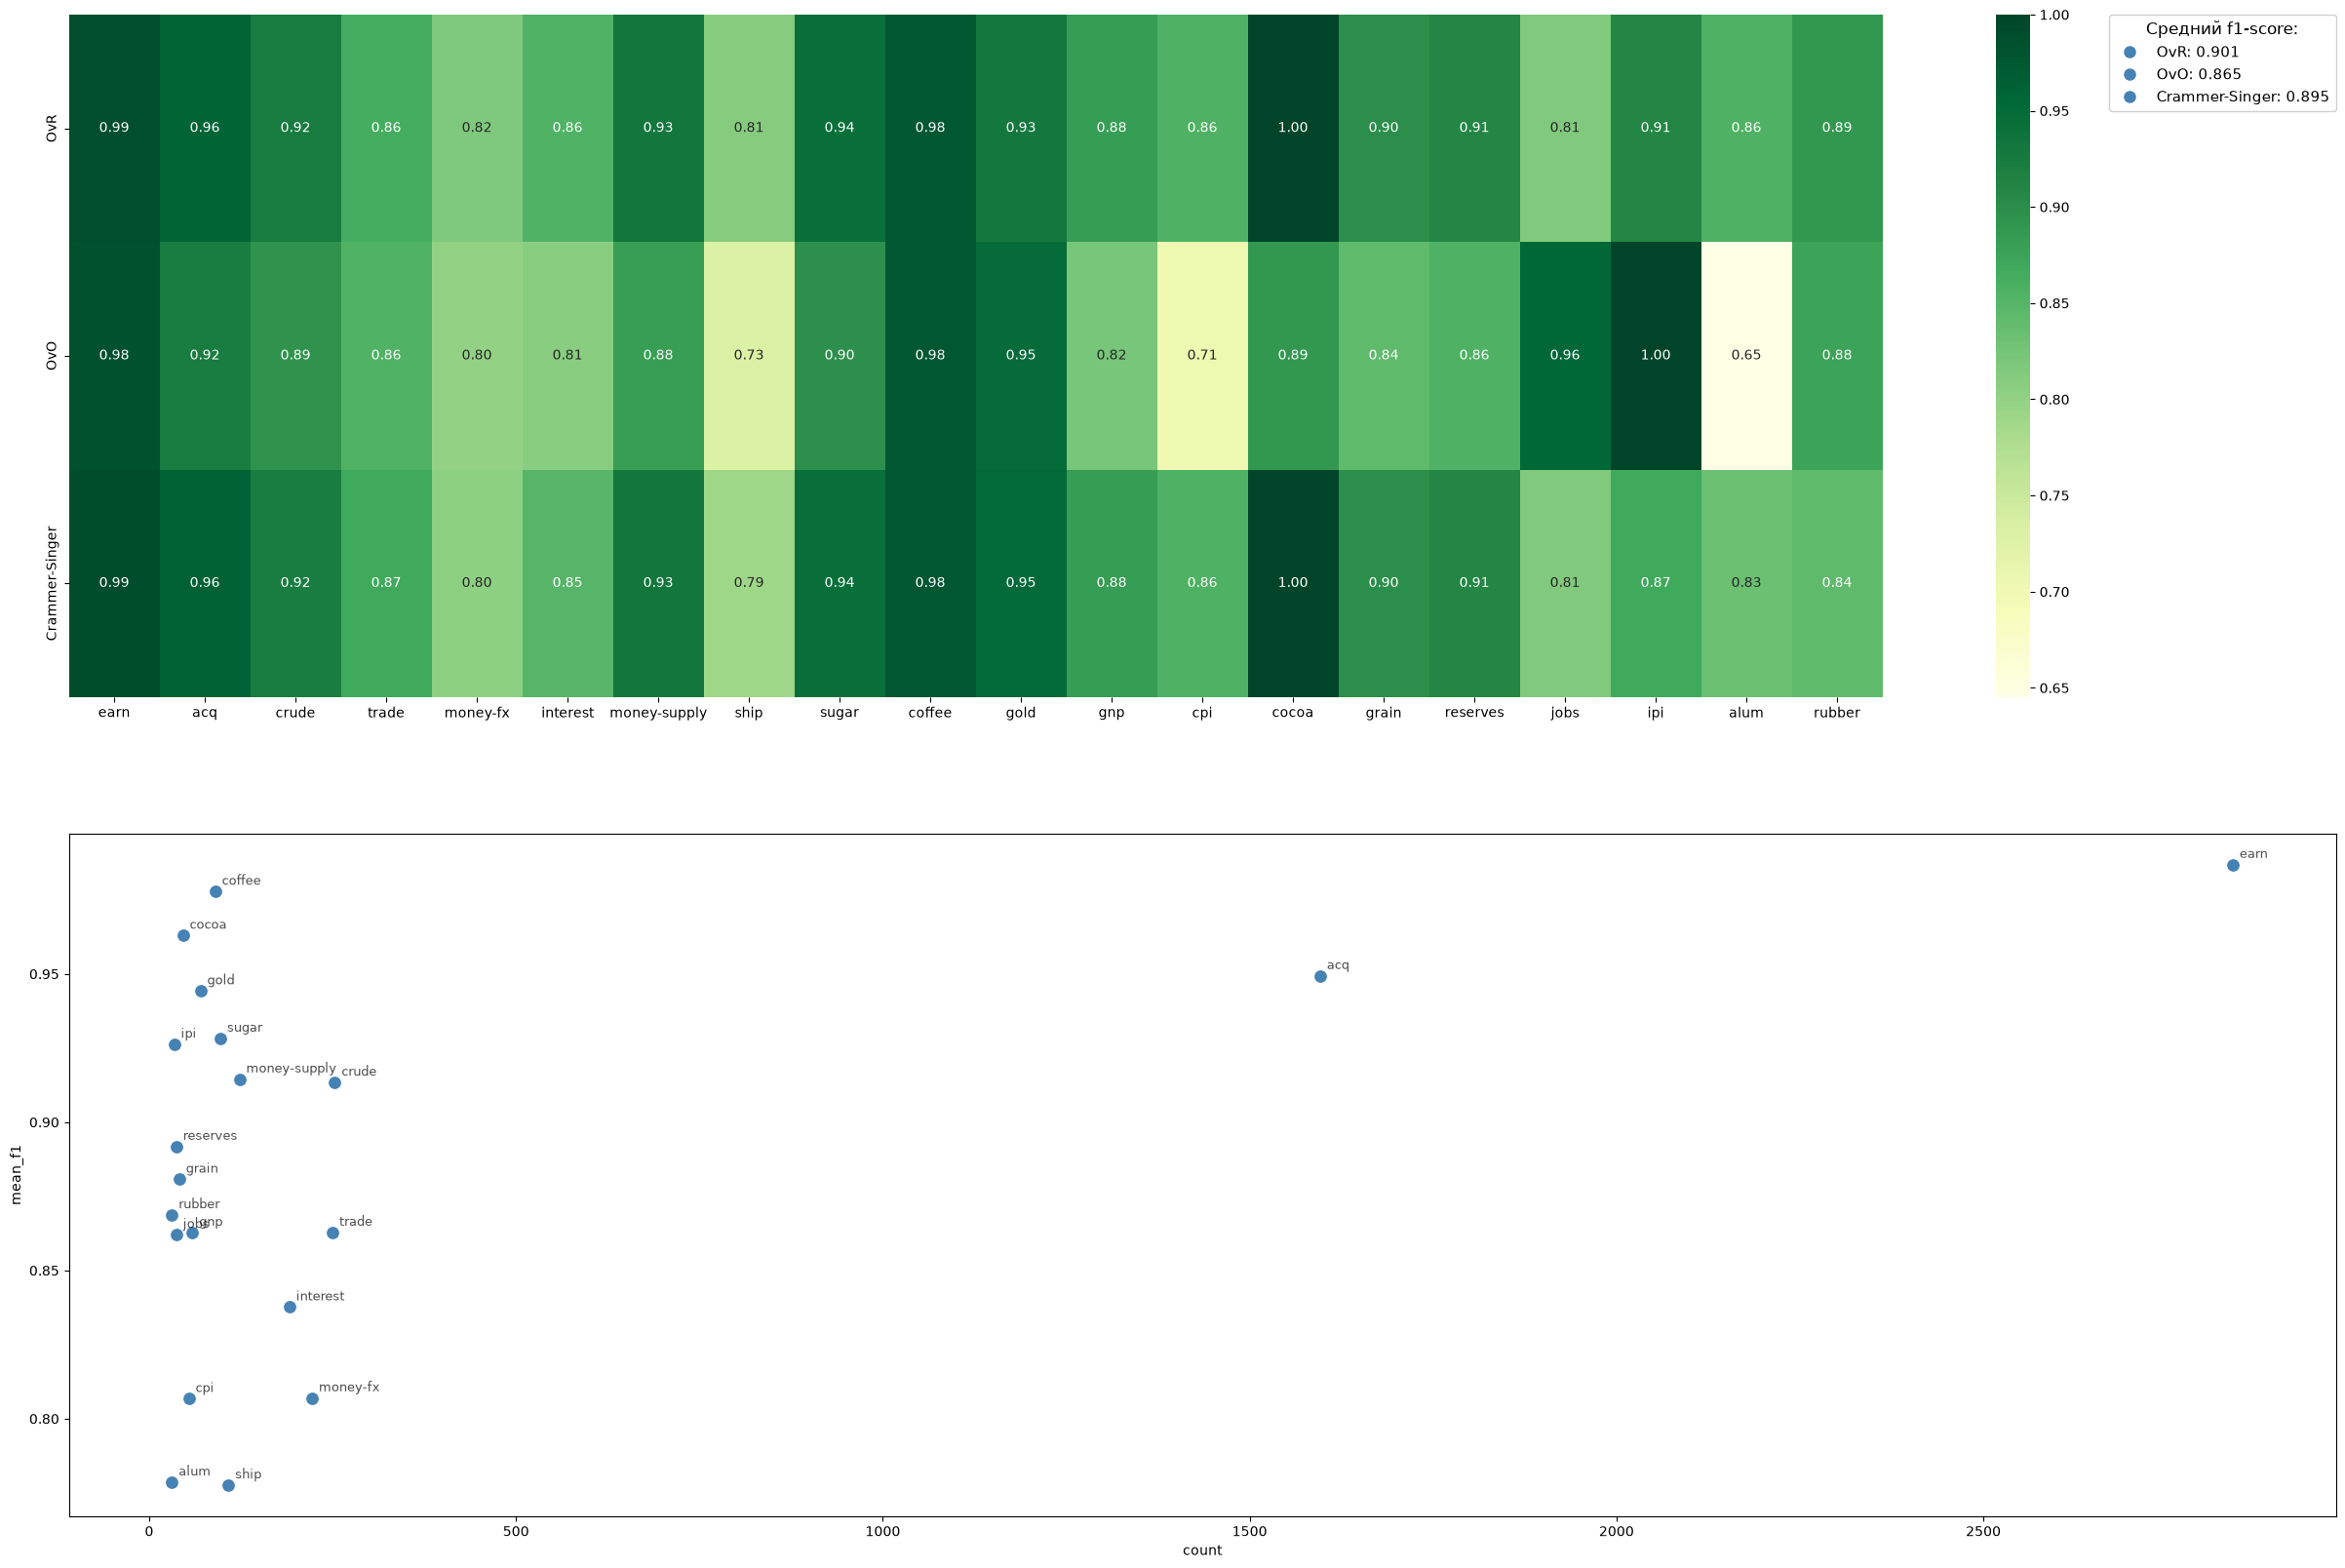

In [26]:
import pandas as pd, seaborn as sns
from sklearn.metrics import f1_score
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt

# heatmap
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(30, 20))

f1 = pd.DataFrame({name: f1_score(tags_test1, m.predict(text_test1), labels=tags, average=None)
                   for name, m in fitted.items()}, index=tags).T
sns.heatmap(f1, annot=True, fmt=".2f", cmap="YlGn", ax=ax1)

# количество тем в датасете
mean_f1 = f1.mean(axis=0)

plot_df = pd.DataFrame({
    "tag": tags,
    "count": counters,
    "mean_f1": mean_f1.values
})

sns.scatterplot(data=plot_df, x="count", y="mean_f1",
                s=100, ax=ax2, color="steelblue")

for _, row in plot_df.iterrows():
    ax2.annotate(row["tag"], (row["count"], row["mean_f1"]),
                 fontsize=9, alpha=0.7,
                 xytext=(5, 5), textcoords="offset points")

handles = [
    Line2D([], [], linestyle="none", marker="o", markersize=8,
           markerfacecolor="steelblue", markeredgecolor="steelblue"),
    Line2D([], [], linestyle="none", marker="o", markersize=8,
        markerfacecolor="steelblue", markeredgecolor="steelblue"),
    Line2D([], [], linestyle="none", marker="o", markersize=8,
        markerfacecolor="steelblue", markeredgecolor="steelblue"),
]
labels = [
    f"OvR: {f1.loc['OvR'].mean():.3f}",
    f"OvO: {f1.loc['OvO'].mean():.3f}",
    f"Crammer-Singer: {f1.loc['Crammer-Singer'].mean():.3f}",
]

ax1.legend(handles=handles, labels=labels,
           loc="upper right",              
           bbox_to_anchor=(1.25, 1),    
           borderaxespad=0,
           fontsize=11, framealpha=0.9,
           title="Средний f1-score:", title_fontsize=12)

plt.show()

## TF-IDF

c:\Users\382he\nlp\.venv\Lib\site-packages\seaborn\matrix.py:309: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set(xlim=(0, self.data.shape[1]), ylim=(0, self.data.shape[0]))


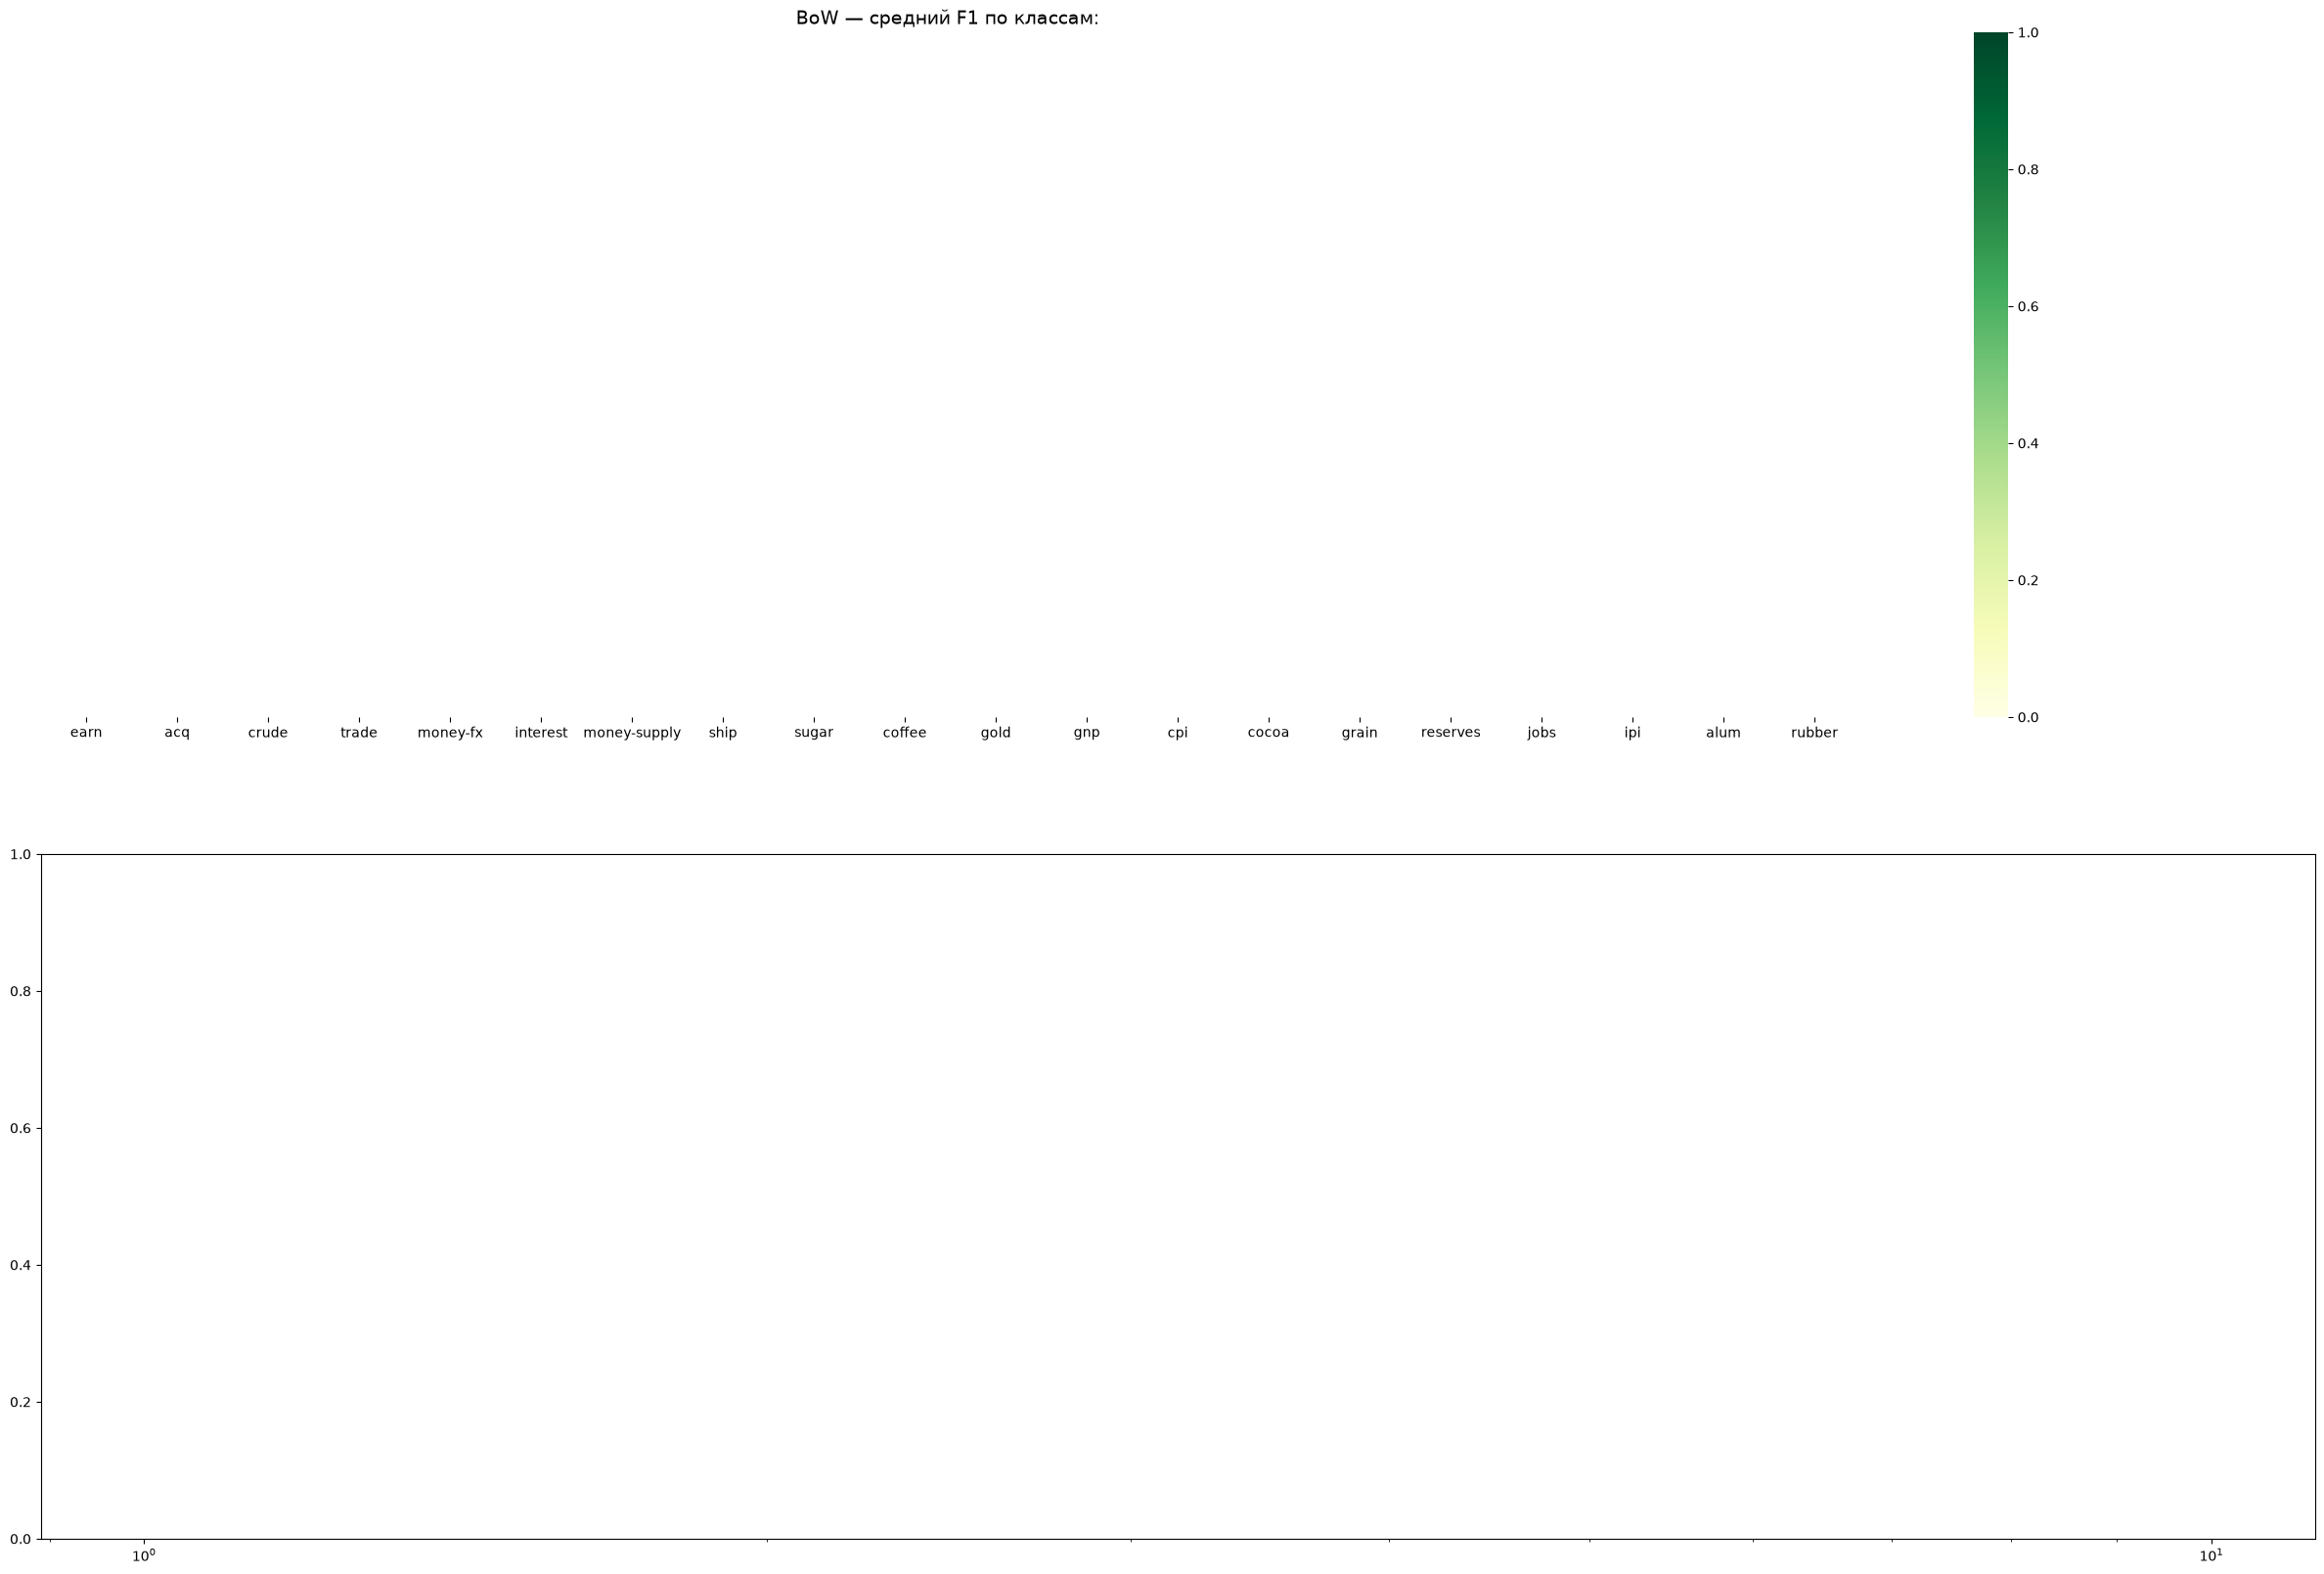

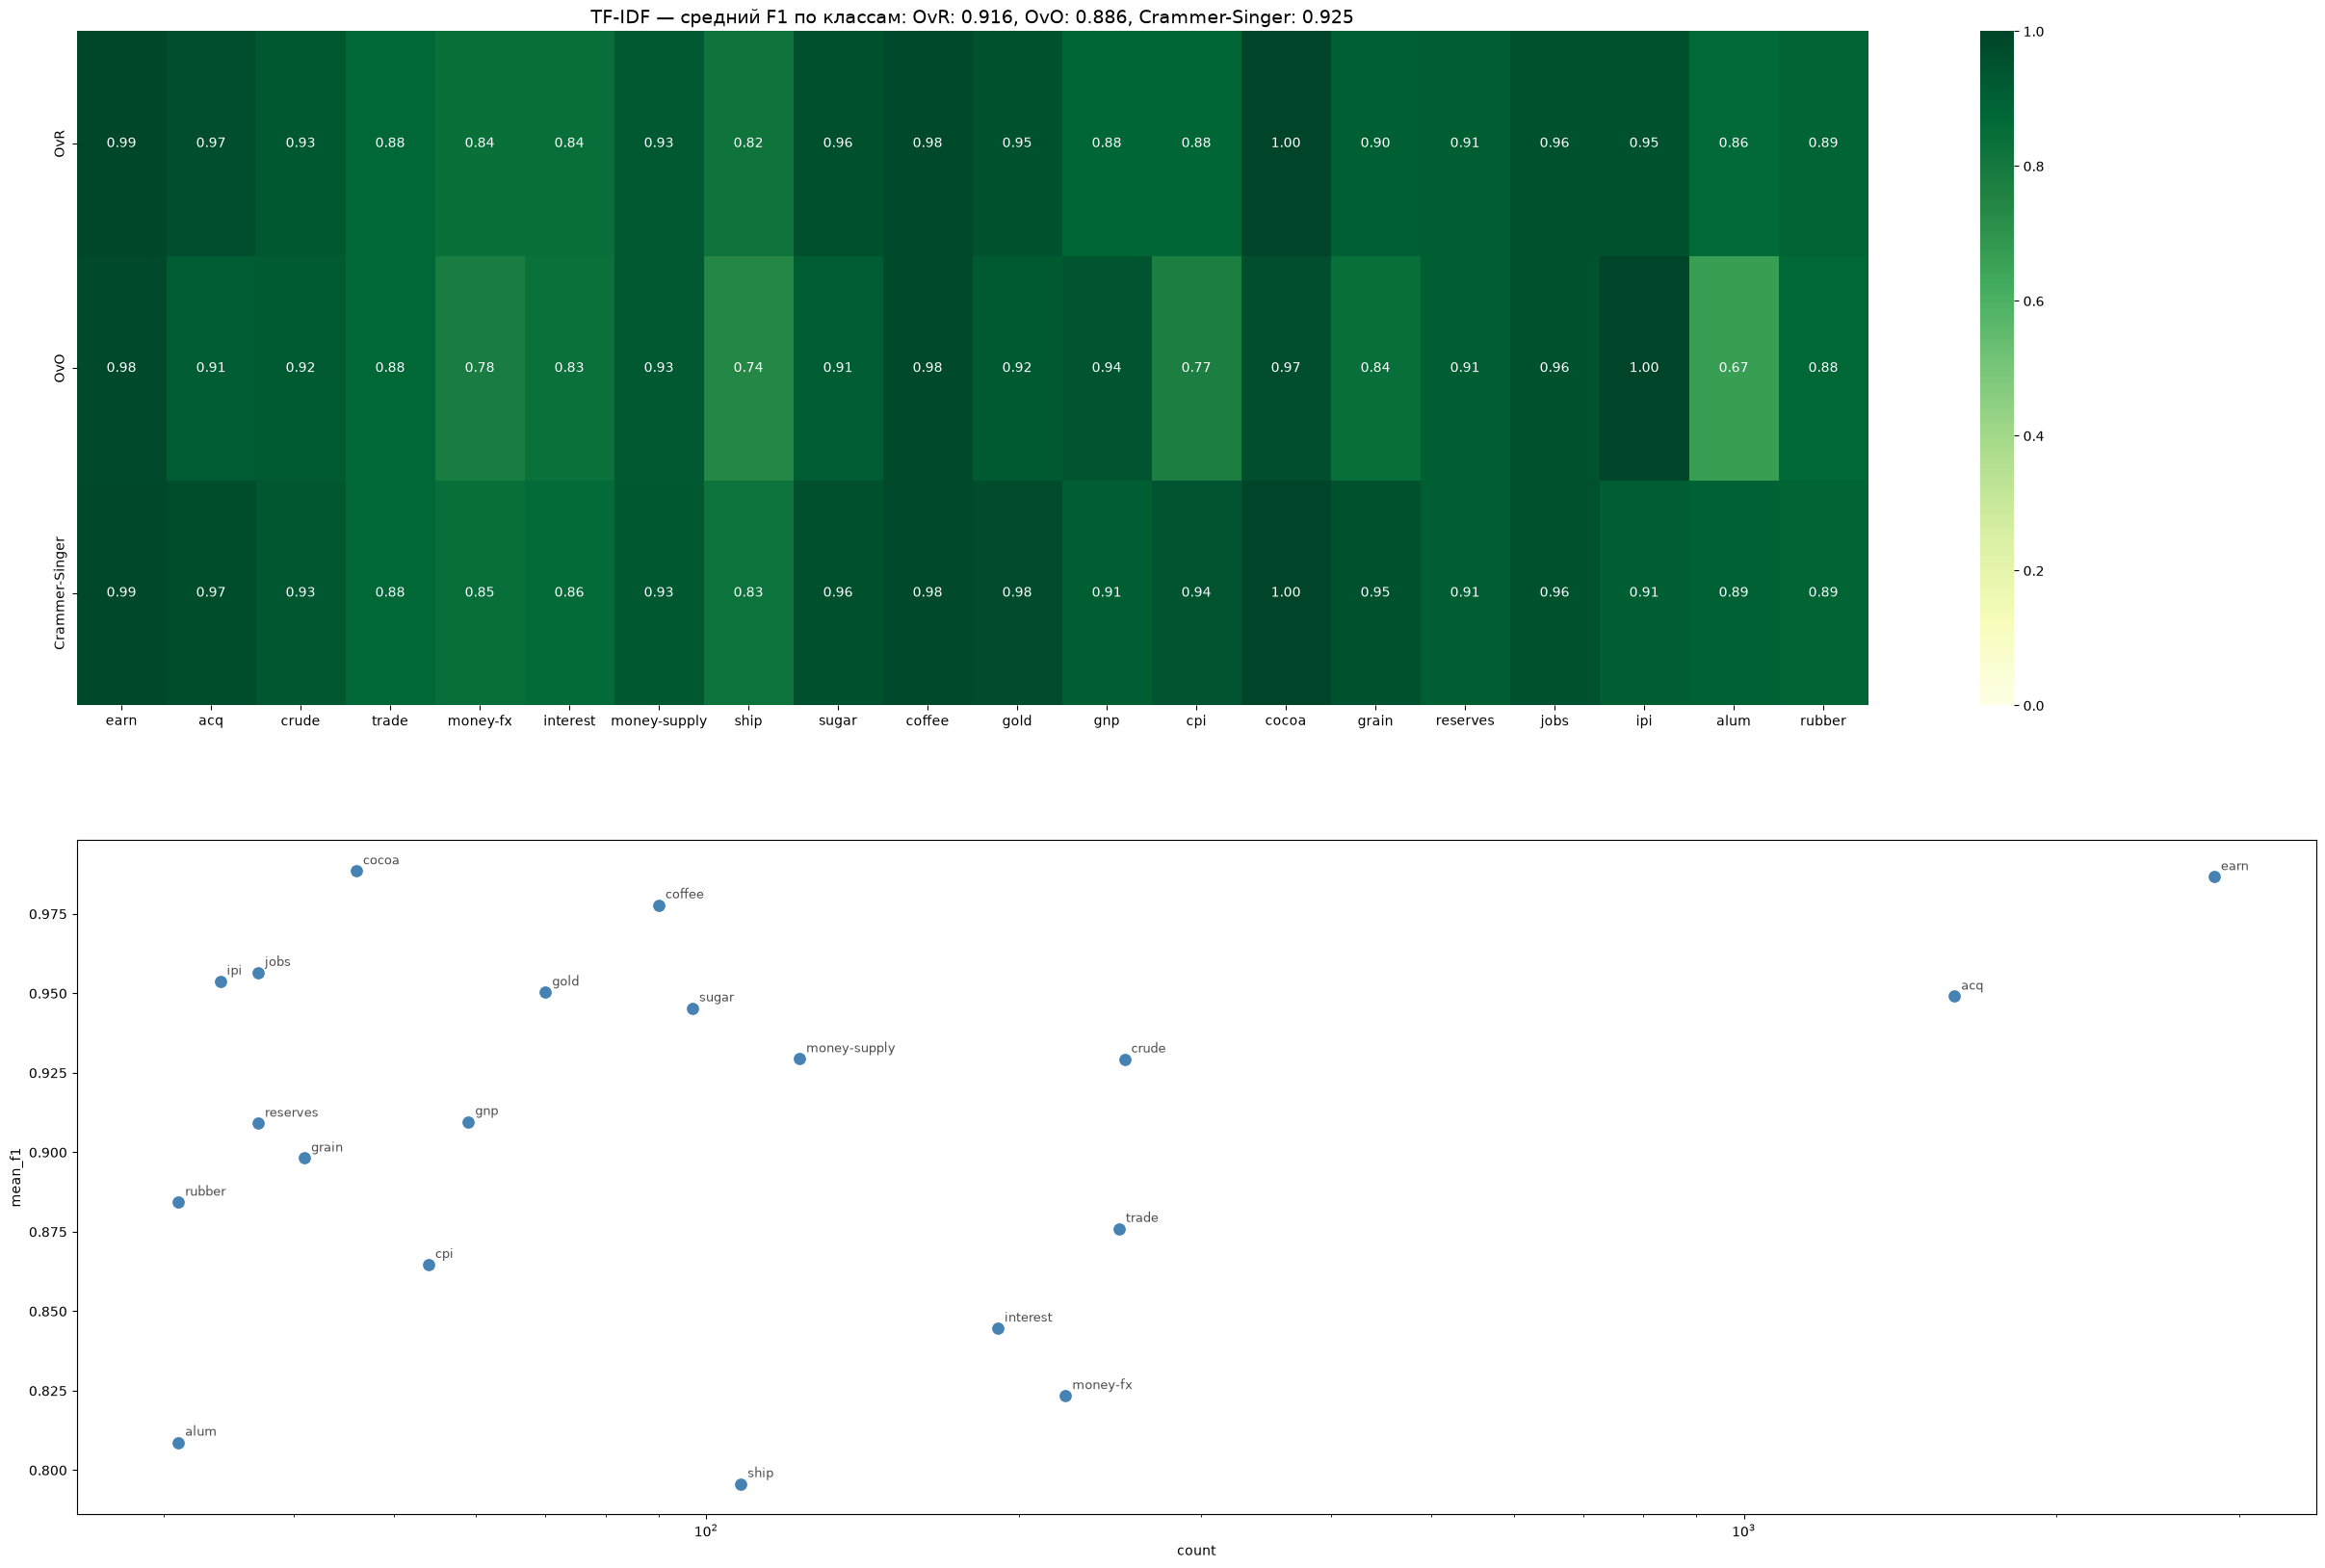

In [32]:
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsOneClassifier
from sklearn.metrics import f1_score

def make_tfidf():  # параметры словаря как в BoW
    return TfidfVectorizer(min_df=2, stop_words="english")

strategies = {
    "OvR": lambda: LinearSVC(C=1),
    "OvO": lambda: OneVsOneClassifier(LinearSVC(C=1)),
    "Crammer-Singer": lambda: LinearSVC(C=1, multi_class="crammer_singer"),
}
fitted_tfidf = {name: make_pipeline(make_tfidf(), make()).fit(text_train1, tags_train1)
                for name, make in strategies.items()}

def plot_f1(models, title):
    f1 = pd.DataFrame({name: f1_score(tags_test1, m.predict(text_test1), labels=tags,
                                      average=None, zero_division=0)
                       for name, m in models.items()}, index=tags).T
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(30, 20))
    sns.heatmap(f1, annot=True, fmt=".2f", cmap="YlGn", vmin=0, vmax=1, ax=ax1)
    means = ", ".join(f"{n}: {v:.3f}" for n, v in f1.mean(axis=1).items())
    ax1.set_title(f"{title} — средний F1 по классам: {means}", fontsize=14)

    plot_df = pd.DataFrame({"tag": tags, "count": counters, "mean_f1": f1.mean(axis=0).values})
    sns.scatterplot(data=plot_df, x="count", y="mean_f1", s=100, ax=ax2, color="steelblue")
    for _, r in plot_df.iterrows():
        ax2.annotate(r["tag"], (r["count"], r["mean_f1"]), fontsize=9, alpha=0.7,
                     xytext=(5, 5), textcoords="offset points")
    ax2.set_xscale("log")
    plt.show()
    return f1

f1_bow = plot_f1(fitted, "BoW")
f1_tfidf = plot_f1(fitted_tfidf, "TF-IDF")

In [30]:
tf_idf_test_scores = tfidf_test.toarray()[0]